# 0. Submission information

**Submission date:** [DD] November 2026

**QPM 2026-2027: Assignment 1**

**Group members:** LOLLI Alessandro, PERALDI Leandrè, MASTROGIACOMO Paolo

**Comments/challenges:** Some S&P 500 tickers could not be downloaded from Yahoo! Finance; as allowed by the assignment, they are ignored. We used Claude (Anthropic) to help structure and debug the code; all results and interpretations were checked by the group.

### Setup
All packages used in the notebook.

In [28]:
%pip install -q yfinance pandas-datareader

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
import pandas_datareader as pdr
import requests
from io import StringIO, BytesIO
from zipfile import ZipFile
from scipy import stats

pd.set_option("display.precision", 4)
pd.set_option("display.width", 120)
plt.rcParams["figure.figsize"] = (9, 4)

Note: you may need to restart the kernel to use updated packages.


# 1. Question 1

## Q1.1
*Download daily stock prices for FAANG stocks (Facebook/Meta, Amazon, Apple, Netflix, Google/Alphabet) from January 2015 until December 2020. The ticker symbols for the five stocks are: META, AMZN, AAPL, NFLX, and GOOG.*

In [19]:
faang = ["META", "AMZN", "AAPL", "NFLX", "GOOG"]

# end is exclusive in yfinance: "2021-01-01" includes 31 December 2020
raw_faang = yf.download(tickers=faang, start="2015-01-01", end="2021-01-01",
                        auto_adjust=False, progress=False)

# Adjusted close prices: corrected for stock splits and dividends (Lecture 1)
prices = raw_faang["Adj Close"][faang].dropna(how="all")
print("Shape (days x stocks):", prices.shape)
print("First date:", prices.index[0].date(), " Last date:", prices.index[-1].date())
prices.head()

Shape (days x stocks): (1511, 5)
First date: 2015-01-02  Last date: 2020-12-31


Ticker,META,AMZN,AAPL,NFLX,GOOG
Date,,,,,
2015-01-02,77.7058,15.4260,24.1718,4.9849,25.9231
2015-01-05,76.4577,15.1095,23.4908,4.7311,25.3827
2015-01-06,75.4276,14.7645,23.4930,4.6501,24.7944
2015-01-07,75.4276,14.9210,23.8224,4.6743,24.7520
2015-01-08,77.4383,15.0230,24.7377,4.7780,24.8300


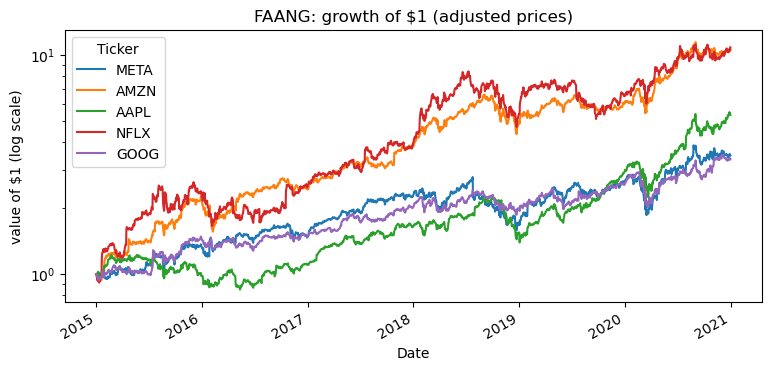

In [20]:
# Growth of $1 invested in each stock on the first day
(prices / prices.iloc[0]).plot(title="FAANG: growth of $1 (adjusted prices)", logy=True)
plt.ylabel("value of $1 (log scale)")
plt.show()

**Answer.** We use the *adjusted* close prices (`Adj Close`), which are corrected for stock splits and dividends, because they measure what an investor actually earns (Lecture 1: e.g., Apple's 4-for-1 split in 2020 and Google's 20-for-1 split in 2022 would otherwise appear as huge negative "returns"). The data are stored in wide format (one column per stock), which is what we need for the matrix computations of the next questions.

## Q1.2
*Compute the first and second moments of stock returns for each of these stocks (i.e., their means, variances, and covariances).*

In [21]:
# Daily simple returns r_t = P_t / P_{t-1} - 1 (computed column by column, i.e., within each stock)
returns = prices.pct_change(fill_method=None).dropna()
print("Number of daily returns:", len(returns))

moments = pd.DataFrame({
    "mean (daily)": returns.mean(),
    "variance (daily)": returns.var(),           # ddof = 1
    "volatility (daily)": returns.std(),
    "mean (annualized)": 252 * returns.mean(),
    "volatility (annualized)": np.sqrt(252) * returns.std()})
moments

Number of daily returns: 1510


,mean (daily),variance (daily),volatility (daily),mean (annualized),volatility (annualized)
Ticker,,,,,
META,0.0010,0.0004,0.0201,0.2593,0.3185
AMZN,0.0018,0.0004,0.0195,0.4411,0.3099
AAPL,0.0013,0.0003,0.0187,0.3233,0.2963
NFLX,0.0019,0.0007,0.0267,0.4873,0.4245
GOOG,0.0009,0.0003,0.0170,0.2377,0.2692


In [22]:
print("Covariance matrix of daily returns:")
display(returns.cov())
print("Covariance matrix, annualized (x 252):")
display(252 * returns.cov())
print("Correlation matrix:")
display(returns.corr().round(2))

Covariance matrix of daily returns:


Ticker,META,AMZN,AAPL,NFLX,GOOG
Ticker,,,,,
META,0.0004,0.0002,0.0002,0.0002,0.0002
AMZN,0.0002,0.0004,0.0002,0.0003,0.0002
AAPL,0.0002,0.0002,0.0003,0.0002,0.0002
NFLX,0.0002,0.0003,0.0002,0.0007,0.0002
GOOG,0.0002,0.0002,0.0002,0.0002,0.0003


Covariance matrix, annualized (x 252):


Ticker,META,AMZN,AAPL,NFLX,GOOG
Ticker,,,,,
META,0.1015,0.0593,0.0543,0.0601,0.0574
AMZN,0.0593,0.0960,0.0508,0.0691,0.0543
AAPL,0.0543,0.0508,0.0878,0.0518,0.0484
NFLX,0.0601,0.0691,0.0518,0.1802,0.0545
GOOG,0.0574,0.0543,0.0484,0.0545,0.0725


Correlation matrix:


Ticker,META,AMZN,AAPL,NFLX,GOOG
Ticker,,,,,
META,1.00,0.60,0.58,0.44,0.67
AMZN,0.60,1.00,0.55,0.53,0.65
AAPL,0.58,0.55,1.00,0.41,0.61
NFLX,0.44,0.53,0.41,1.00,0.48
GOOG,0.67,0.65,0.61,0.48,1.00


In [23]:
corr = returns.corr().values
avg_corr = corr[np.triu_indices_from(corr, k=1)].mean()
print(f"Average pairwise correlation: {avg_corr:.2f}")
print(f"Highest annualized mean: {moments['mean (annualized)'].idxmax()} "
      f"({moments['mean (annualized)'].max():.1%})")
print(f"Highest annualized volatility: {moments['volatility (annualized)'].idxmax()} "
      f"({moments['volatility (annualized)'].max():.1%})")

Average pairwise correlation: 0.55
Highest annualized mean: NFLX (48.7%)
Highest annualized volatility: NFLX (42.5%)


**Answer.** The tables report the first moments (means) and second moments (variances and the full covariance matrix) of daily simple returns, both at daily frequency and annualized (mean × 252, variance × 252, volatility × √252).

* All five stocks had high average returns over 2015–2020, a period that was exceptionally good for large technology firms (keep in mind that a sample mean over 6 years is very imprecise: with an annual volatility of about 30%, its standard error is about 30%/√6 ≈ 12%, Lecture 1).
* All covariances are positive and the correlations are substantial: the FAANG stocks share a common "big tech" component, so combining them gives only limited diversification (the variance of a portfolio depends mainly on the covariances, Lecture 3).

## Q1.3
*Compute the skewness and excess kurtosis for the returns for each of these stocks. Do the daily stock returns have a Normal distribution?*

In [24]:
T = len(returns)
dist = pd.DataFrame({
    "skewness": returns.skew(),
    "excess kurtosis": returns.kurt(),                   # pandas .kurt() = EXCESS kurtosis (Normal = 0)
    "z-stat skewness": returns.skew() / np.sqrt(6 / T),  # under Normality S ~ N(0, 6/T)
    "z-stat excess kurtosis": returns.kurt() / np.sqrt(24 / T),   # K - 3 ~ N(0, 24/T)
    "Jarque-Bera stat": [stats.jarque_bera(returns[c]).statistic for c in returns],
    "JB p-value": [stats.jarque_bera(returns[c]).pvalue for c in returns]})
dist

,skewness,excess kurtosis,z-stat skewness,z-stat excess kurtosis,Jarque-Bera stat,JB p-value
Ticker,,,,,,
META,-0.3304,12.0508,-5.2415,95.5873,9097.9936,0.0
AMZN,0.7605,7.2036,12.0647,57.1387,3384.9463,0.0
AAPL,-0.0821,6.6136,-1.3026,52.4593,2732.2037,0.0
NFLX,0.6802,7.3406,10.7902,58.2255,3480.3540,0.0
GOOG,0.5172,10.4394,8.2056,82.8055,6873.4602,0.0


,days with |z| > 4,expected if Normal
Ticker,,
META,13,0.1
AMZN,9,0.1
AAPL,10,0.1
NFLX,9,0.1
GOOG,11,0.1


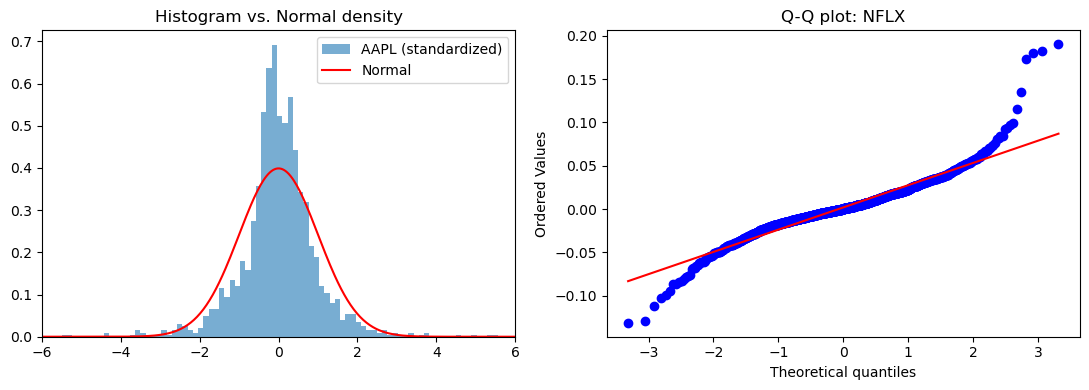

Stocks for which Normality is NOT rejected at 5%: none


In [25]:
# Extreme days: moves larger than 4 standard deviations vs. number expected under a Normal
z = (returns - returns.mean()) / returns.std()
extremes = pd.DataFrame({"days with |z| > 4": (z.abs() > 4).sum(),
                         "expected if Normal": T * 2 * stats.norm.sf(4)})
display(extremes.round(2))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(z["AAPL"], bins=100, density=True, alpha=0.6, label="AAPL (standardized)")
xx = np.linspace(-6, 6, 300)
ax[0].plot(xx, stats.norm.pdf(xx), "r", label="Normal")
ax[0].set_xlim(-6, 6); ax[0].legend(); ax[0].set_title("Histogram vs. Normal density")
stats.probplot(returns["NFLX"], dist="norm", plot=ax[1]); ax[1].set_title("Q-Q plot: NFLX")
plt.tight_layout(); plt.show()

normal = (dist["JB p-value"] > 0.05)
print("Stocks for which Normality is NOT rejected at 5%:", list(dist.index[normal]) or "none")

**Answer. No, daily returns are not Normally distributed.**

* For a Normal distribution skewness is 0 and excess kurtosis is 0 (kurtosis 3). With about 1,500 daily observations the standard errors under Normality are only √(6/T) ≈ 0.06 for skewness and √(24/T) ≈ 0.13 for kurtosis, so the estimated excess kurtosis (far above 0 for every stock) is many standard errors away from the Normal value.
* The Jarque–Bera test, JB = T[S²/6 + (K−3)²/24] ~ χ²(2), rejects Normality with p-values that are essentially zero.
* The number of days with moves larger than four standard deviations is far higher than the number a Normal distribution predicts (which is less than one), and the Q-Q plot bends away from the straight line in both tails: daily returns have **fat tails** (e.g., the March 2020 Covid crash and large earnings-day jumps such as Netflix and Meta).
* Skewness is non-zero as well; its sign differs across stocks.

This is consistent with Lecture 1: at short horizons returns have weak skewness and strong excess kurtosis.

# 2. Question 2

## Q2.1
*Prepare the data for this question. Download from Wikipedia (or any other source) a table that lists the companies that comprise the S&P 500. From this table, extract the list of ticker symbols. Set start date = "2000-01-01" and end date = "2022-12-31". Build a dataframe that contains the month-end adjusted stock prices for the S&P 500 companies (if there are errors for some company names, it is fine to ignore them). Drop the columns that have only "NaN" entries. Drop also company names with more than 100 missing monthly observations.*

In [26]:
def get_sp500_table():
    # Wikipedia first (a browser User-Agent avoids a 403 error); GitHub dataset as a fallback
    try:
        url = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"
        html = requests.get(url, headers={"User-Agent": "Mozilla/5.0"}, timeout=30).text
        table = pd.read_html(StringIO(html))[0]
        print("Ticker list downloaded from Wikipedia")
    except Exception as e:
        print("Wikipedia failed (", type(e).__name__, "): using the GitHub dataset instead")
        table = pd.read_csv("https://raw.githubusercontent.com/datasets/"
                            "s-and-p-500-companies/main/data/constituents.csv")
    return table

sp500 = get_sp500_table()
# Yahoo uses "-" instead of "." in share-class tickers (BRK.B -> BRK-B, BF.B -> BF-B)
tickers = sp500["Symbol"].astype(str).str.replace(".", "-", regex=False).tolist()
print("Number of tickers:", len(tickers))
print(tickers[:12])

Ticker list downloaded from Wikipedia
Number of tickers: 503
['MMM', 'AOS', 'ABT', 'ABBV', 'ACN', 'ADBE', 'AMD', 'AES', 'AFL', 'A', 'APD', 'ABNB']


In [14]:
start_date, end_date = "2000-01-01", "2022-12-31"

# Daily adjusted prices for all tickers (takes a few minutes); failed tickers are simply missing
raw = yf.download(tickers=tickers, start=start_date, end=end_date,
                  auto_adjust=False, progress=False, threads=True)
daily = raw["Adj Close"]
print("Daily prices:", daily.shape)

# Month-end prices: last available price of each month
monthly = daily.resample("ME").last()
n_start = monthly.shape[1]

monthly = monthly.dropna(axis=1, how="all")                 # columns with only NaN (failed downloads)
n_after_nan = monthly.shape[1]
monthly = monthly.loc[:, monthly.isna().sum() <= 100]       # more than 100 missing months
print(f"Tickers requested: {n_start}; after dropping all-NaN columns: {n_after_nan}; "
      f"after dropping > 100 missing months: {monthly.shape[1]}")
print("Months:", monthly.shape[0], "from", monthly.index[0].date(), "to", monthly.index[-1].date())
monthly.iloc[:5, :8]

$HONA: Data doesn't exist for startDate = 946702800, endDate = 1672462800
$SOLV: Data doesn't exist for startDate = 946702800, endDate = 1672462800
$RDDT: Data doesn't exist for startDate = 946702800, endDate = 1672462800
$GEV: Data doesn't exist for startDate = 946702800, endDate = 1672462800
$Q: Data doesn't exist for startDate = 946702800, endDate = 1672462800
$VLTO: Data doesn't exist for startDate = 946702800, endDate = 1672462800
$SNDK: Data doesn't exist for startDate = 946702800, endDate = 1672462800
$VYLR: Data doesn't exist for startDate = 946702800, endDate = 1672462800
$FDXF: Data doesn't exist for startDate = 946702800, endDate = 1672462800

9 Failed downloads:
['HONA', 'SOLV', 'RDDT', 'GEV', 'Q', 'VLTO', 'SNDK', 'VYLR', 'FDXF']: Data doesn't exist for startDate = 946702800, endDate = 1672462800


Daily prices: (5787, 503)
Tickers requested: 503; after dropping all-NaN columns: 494; after dropping > 100 missing months: 412
Months: 276 from 2000-01-31 to 2022-12-31


Ticker,A,AAPL,ABT,ACGL,ACN,ADBE,ADI,ADM
Date,,,,,,,,
2000-01-31,39.3376,0.7758,7.4203,1.5452,NaN,13.6682,28.4010,5.7695
2000-02-29,61.7367,0.8571,7.5200,1.6112,NaN,25.3196,47.7654,4.9616
2000-03-31,61.8109,1.0155,8.0185,1.7301,NaN,27.6380,48.9045,5.0849
2000-04-30,52.6730,0.9277,8.8031,1.6261,NaN,30.0278,46.6643,4.9000
2000-05-31,43.7580,0.6281,9.3184,1.5848,NaN,27.9484,46.7782,5.9148


**Answer.** The ticker list comes from the Wikipedia table "List of S&P 500 companies" (with a GitHub copy of the same list as a fallback). Tickers with a dot are converted to Yahoo's format with a dash. We download daily adjusted prices and keep the last price of each month (`resample("ME").last()`), which gives month-end adjusted prices from January 2000 to December 2022 (276 months). Columns with only missing values (tickers that failed to download) are dropped, and so are companies with more than 100 missing months (mostly firms that listed after about 2008). The number of remaining companies is printed above.

*Note:* the list contains **today's** constituents of the S&P 500, so the sample suffers from survivorship bias (Lecture 1): firms that were delisted or left the index between 2000 and 2022 are not included.

## Q2.2
*Compute the simple monthly returns for the companies in your dataset (and save them to a file, because Assignment 2 uses them again).*

In [15]:
# Simple monthly returns R_t = P_t / P_{t-1} - 1; the first month (January 2000) has no return
ret = monthly.pct_change(fill_method=None).iloc[1:]
print("Monthly returns:", ret.shape, "from", ret.index[0].date(), "to", ret.index[-1].date())

ret.to_csv("sp500_monthly_returns.csv")
monthly.to_csv("sp500_monthly_prices.csv")
print("Saved: sp500_monthly_returns.csv and sp500_monthly_prices.csv")
# In Colab, download the files or save them to Google Drive, because the session storage is temporary:
# from google.colab import files; files.download("sp500_monthly_returns.csv")
ret.iloc[:5, :8]

Monthly returns: (275, 412) from 2000-02-29 to 2022-12-31
Saved: sp500_monthly_returns.csv and sp500_monthly_prices.csv


Ticker,A,AAPL,ABT,ACGL,ACN,ADBE,ADI,ADM
Date,,,,,,,,
2000-02-29,0.5694,0.1048,0.0134,0.0427,NaN,0.8524,0.6818,-0.1400
2000-03-31,0.0012,0.1848,0.0663,0.0738,NaN,0.0916,0.0238,0.0248
2000-04-30,-0.1478,-0.0865,0.0978,-0.0601,NaN,0.0865,-0.0458,-0.0364
2000-05-31,-0.1693,-0.3229,0.0585,-0.0254,NaN,-0.0693,0.0024,0.2071
2000-06-30,0.0017,0.2470,0.0952,-0.0042,NaN,0.1551,-0.0130,-0.1780


**Answer.** Simple monthly returns are computed from month-end adjusted prices, so they include dividends. The returns run from February 2000 to December 2022 (275 months) and are saved to `sp500_monthly_returns.csv`, which Assignment 2 reads again.

## Q2.3
*Compute the annualized mean return, volatility, and Sharpe ratio for these companies in your dataset. For the Sharpe ratio, use the monthly risk-free rate (RF) from Ken French's data library, which you can download with pandas datareader as shown in Lecture 1.*

In [16]:
def get_ff_rf(start, end):
    # Monthly risk-free rate from Ken French's data library (in percent -> decimal)
    try:
        ff = pdr.DataReader("F-F_Research_Data_Factors", "famafrench", start=start, end=end)[0]
        rf = ff["RF"] / 100
    except Exception as e:
        # Fallback: read the CSV inside the zip file directly from the data library
        print("pandas-datareader failed (", type(e).__name__, "): reading the zip file directly")
        url = ("https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/"
               "F-F_Research_Data_Factors_CSV.zip")
        z = ZipFile(BytesIO(requests.get(url, timeout=30).content))
        df = pd.read_csv(z.open(z.namelist()[0]), skiprows=3, index_col=0)
        df.index = df.index.astype(str).str.strip()
        df = df[df.index.str.fullmatch(r"\d{6}")]              # monthly rows only (yyyymm)
        rf = df["RF"].astype(float) / 100
        rf.index = pd.PeriodIndex(pd.to_datetime(rf.index, format="%Y%m"), freq="M")
        rf = rf[(rf.index >= pd.Period(start[:7], "M")) & (rf.index <= pd.Period(end[:7], "M"))]
    rf.index = pd.PeriodIndex(rf.index, freq="M")
    return rf

rf = get_ff_rf(start_date, end_date)
print("Risk-free rate: ", rf.index[0], "to", rf.index[-1], f"| average annual RF = {12 * rf.mean():.2%}")

# Align stock returns (month-end timestamps) and RF (monthly periods) on months
ret_p = ret.copy()
ret_p.index = ret_p.index.to_period("M")
excess = ret_p.sub(rf, axis=0)

stats_sp = pd.DataFrame({
    "mean (ann.)": 12 * ret.mean(),
    "volatility (ann.)": np.sqrt(12) * ret.std(),
    "Sharpe ratio (ann.)": np.sqrt(12) * excess.mean() / excess.std()})
print("Cross-sectional summary across companies:")
display(stats_sp.describe().round(3))
print("Ten companies with the highest Sharpe ratio:")
display(stats_sp.sort_values("Sharpe ratio (ann.)", ascending=False).head(10).round(3))

Risk-free rate:  2000-01 to 2022-12 | average annual RF = 1.49%
Cross-sectional summary across companies:


,mean (ann.),volatility (ann.),Sharpe ratio (ann.)
count,412.000,412.000,412.000
mean,0.166,0.325,0.485
std,0.066,0.117,0.176
min,0.011,0.158,-0.012
25%,0.120,0.246,0.356
50%,0.157,0.297,0.483
75%,0.199,0.380,0.611
max,0.477,0.944,1.010


Ten companies with the highest Sharpe ratio:


,mean (ann.),volatility (ann.),Sharpe ratio (ann.)
Ticker,,,
MA,0.314,0.302,1.010
TDG,0.285,0.280,0.983
AWK,0.177,0.186,0.924
UNH,0.232,0.242,0.894
MNST,0.392,0.426,0.884
V,0.210,0.233,0.879
ODFL,0.300,0.327,0.870
AZO,0.230,0.248,0.867
ORLY,0.251,0.283,0.835


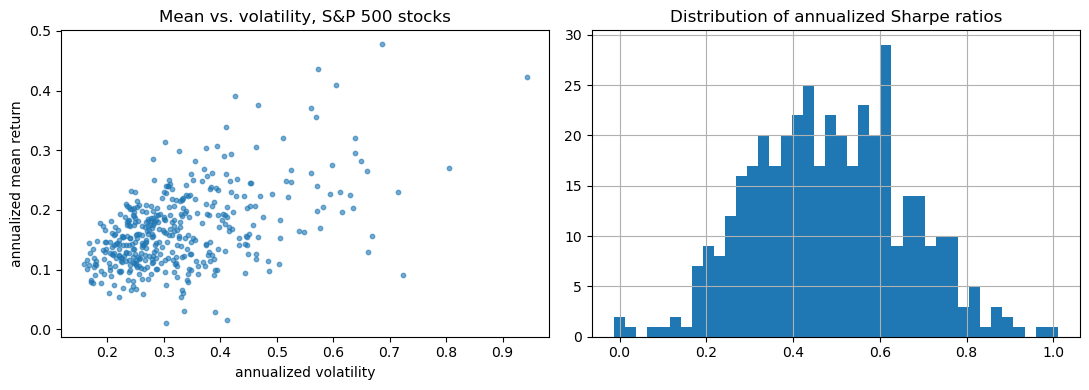

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(stats_sp["volatility (ann.)"], stats_sp["mean (ann.)"], s=10, alpha=0.6)
ax[0].set_xlabel("annualized volatility"); ax[0].set_ylabel("annualized mean return")
ax[0].set_title("Mean vs. volatility, S&P 500 stocks")
stats_sp["Sharpe ratio (ann.)"].hist(bins=40, ax=ax[1])
ax[1].set_title("Distribution of annualized Sharpe ratios")
plt.tight_layout(); plt.show()

**Answer.** For each company:
* annualized mean = 12 × average monthly return;
* annualized volatility = √12 × standard deviation of monthly returns;
* annualized Sharpe ratio = √12 × mean(R − RF) / std(R − RF), using the **excess** return over the monthly risk-free rate from Ken French's data library (Lecture 2). Annualizing with √12 is exact only if returns are not autocorrelated (Lo 2002).

The tables show the distribution across companies and the companies with the highest Sharpe ratios; the scatter plot shows how mean returns relate to volatility across individual stocks; according to the theory only systematic risk (beta), not total volatility, should be rewarded (Lecture 3), so we should not expect a tight relation between the two.

## Q2.4
*Would it make sense to choose portfolio weights based only on the Sharpe ratios of the stocks in your dataset? Explain the reasons for your answer.*

In [18]:
# Supporting evidence 1: Sharpe ratios are estimated with a lot of error
T_m = ret.notna().sum()                                   # months of data per stock
sr_m = stats_sp["Sharpe ratio (ann.)"] / np.sqrt(12)      # monthly SR
se_ann = np.sqrt(12) * np.sqrt((1 + 0.5 * sr_m**2) / T_m)  # delta-method SE (Lecture 2)
print(f"Median standard error of an annualized Sharpe ratio: {se_ann.median():.2f}")
print(f"Median annualized Sharpe ratio: {stats_sp['Sharpe ratio (ann.)'].median():.2f}")

# Supporting evidence 2: are high Sharpe ratios persistent? Rank on 2000-2011, evaluate on 2012-2022
first, second = excess.loc[:"2011"], excess.loc["2012":]
sr1 = np.sqrt(12) * first.mean() / first.std()
sr2 = np.sqrt(12) * second.mean() / second.std()
both = pd.concat([sr1, sr2], axis=1, keys=["SR 2000-2011", "SR 2012-2022"]).dropna()
top = both["SR 2000-2011"] >= both["SR 2000-2011"].quantile(0.9)
print(f"\nCorrelation between Sharpe ratios in the two halves: {both.corr().iloc[0, 1]:.2f}")
print(f"Average SR in 2012-2022 of the top-10% stocks of 2000-2011: {both.loc[top, 'SR 2012-2022'].mean():.2f}")
print(f"Average SR in 2012-2022 of all other stocks:            {both.loc[~top, 'SR 2012-2022'].mean():.2f}")

# Supporting evidence 3: high-Sharpe stocks can be highly correlated with each other
best10 = stats_sp["Sharpe ratio (ann.)"].nlargest(10).index
c = ret[best10].corr().values
print(f"\nAverage correlation among the 10 highest-Sharpe stocks: {c[np.triu_indices_from(c, 1)].mean():.2f}")

Median standard error of an annualized Sharpe ratio: 0.21
Median annualized Sharpe ratio: 0.48

Correlation between Sharpe ratios in the two halves: 0.01
Average SR in 2012-2022 of the top-10% stocks of 2000-2011: 0.64
Average SR in 2012-2022 of all other stocks:            0.65

Average correlation among the 10 highest-Sharpe stocks: 0.25


**Answer. No, it would not make sense to choose portfolio weights based only on the individual Sharpe ratios.** The reasons, from Lectures 1–3:

1. **It ignores correlations.** The Sharpe ratio is a good measure for a whole (efficient) portfolio, not for individual assets, because it ignores how an asset co-moves with the other assets (Lecture 2). In a portfolio, what matters is an asset's contribution to portfolio risk, σₙₚ/σₚ, not its own volatility (Lecture 3). Two stocks with high Sharpe ratios that are highly correlated provide little diversification, while a stock with a lower Sharpe ratio that is weakly correlated with the rest can reduce portfolio risk a lot. The optimal mean-variance weights are w = (1/γ) V⁻¹(μ − R_f 1), which use the full covariance matrix V; ranking on Sharpe ratios would be optimal only if all correlations were zero (and even then the weights would be proportional to SRₙ/σₙ, not to SRₙ).
2. **Estimation error.** Sharpe ratios are estimated imprecisely: the standard error is √((1 + SR²/2)/T), about 0.2 per year with 23 years of monthly data (see the output above), which is as large as many of the differences across stocks. Most differences between the stocks' Sharpe ratios are not statistically significant. The split-sample check above shows how much the ranking of stocks changes between 2000–2011 and 2012–2022.
3. **Look-ahead (in-sample) bias.** The Sharpe ratios are computed over the full sample 2000–2022. Using them to form a portfolio and then evaluating it over the same period is an in-sample exercise; an honest evaluation requires weights based only on past data (out-of-sample, Lecture 2).
4. **Survivorship bias.** The sample consists of *today's* S&P 500 constituents, i.e., firms that survived and grew. Their past returns, and hence their Sharpe ratios, are biased upwards (Lecture 1, Python exercise 7).
5. **Multiple testing / data snooping.** Picking the best stocks out of several hundred will find high Sharpe ratios by luck alone (Lecture 2, Python exercise 5).
6. **Other limitations.** The Sharpe ratio uses only the first two moments (it ignores skewness and fat tails), and a rule based on recent Sharpe ratios can generate high turnover and transaction costs.

A better approach is to use the whole covariance matrix and to reduce the effect of estimation error (shrinkage, constraints, or the global-minimum-variance portfolio), as studied in Lecture 4 and in Assignment 2.